# Notebook 03 — Reproduce the Stanford Goodreads Popularity Experiments

This notebook consumes `goodreads_paper_features.csv` from Notebook 02 and implements the experiment structure described in the paper and repository.

## Feature subsets
- **A:** `user_reviews`, `days_since_review`, `user_rating`, `rating_diff`
- **B:** A + `num_words`, `avg_word_len`, `avg_sent_len`, `pct_verbs`, `pct_nouns`, `pct_adj`, `quote`, `sentiment`
- **C:** B + Bag-of-Words (top 10,000 terms)
- **D:** B + TF-IDF

## Experiment grid
- Logistic Regression: A/B with and without training undersampling; C/D undersampled.
- XGBoost: A/B with and without training undersampling; C/D undersampled.
- Neural network: A/B with and without training undersampling; C/D undersampled.
- 70/15/15 train/validation/test split (15% held out for final testing and 15% for validation).
- Undersampling is applied to the training partition only.
- Metrics use a 0.5 classification threshold to match the paper's reported classification table; ROC-AUC uses probabilities.

## Safe execution modes
`QUICK_RUN=True` uses smaller XGBoost trees and a shorter neural-network epoch budget to validate the complete pipeline. Set it to `False` for the paper-scale settings. `MAX_ROWS=150_000` is a development pilot; set it to `None` for the full processed dataset. Pilot results must not be reported as full-data reproduction.

The paper's original neural network uses a single hidden layer with approximately two-thirds as many nodes as input features, sigmoid output, binary cross-entropy, Adam, mini-batches and early stopping. Text features are kept sparse until individual neural-network batches are converted to dense arrays.

## 1. Install dependencies

In [1]:
%pip -q install pandas numpy scipy scikit-learn xgboost tensorflow joblib matplotlib seaborn

## 2. Mount Drive and configure the run

In [2]:
from pathlib import Path
import os, json, time, gc, warnings, traceback
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from google.colab import drive

drive.mount('/content/drive')

DRIVE = Path('/content/drive/MyDrive')
OUTPUT_DIR = DRIVE / 'goodreads_reproduction_results'
MODEL_DIR = OUTPUT_DIR / 'models'
PLOT_DIR = OUTPUT_DIR / 'plots'
PRED_DIR = OUTPUT_DIR / 'predictions'
for p in [OUTPUT_DIR, MODEL_DIR, PLOT_DIR, PRED_DIR]:
    p.mkdir(parents=True, exist_ok=True)

DATA_PATH = OUTPUT_DIR / 'goodreads_paper_features.csv'
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f'{DATA_PATH} not found. Run Notebook 02 to completion first.'
    )

# Start with this configuration to validate the full pipeline.
QUICK_RUN = True
MAX_ROWS = 100_000     # Set None for all rows in the final run.
MAX_TEXT_FEATURES = 10_000
RANDOM_STATE = 229
TEST_SIZE = 0.15
VALIDATION_SIZE = 0.15

print('Input:', DATA_PATH)
print('Output:', OUTPUT_DIR)
print('QUICK_RUN:', QUICK_RUN, '| MAX_ROWS:', MAX_ROWS)

Mounted at /content/drive
Input: /content/drive/MyDrive/goodreads_reproduction_results/goodreads_paper_features.csv
Output: /content/drive/MyDrive/goodreads_reproduction_results
QUICK_RUN: True | MAX_ROWS: 100000


## 3. Load required columns and take a reproducible stratified pilot

In [3]:
from sklearn.model_selection import train_test_split

A_COLS = ['user_reviews', 'days_since_review', 'user_rating', 'rating_diff']
B_EXTRA_COLS = [
    'num_words', 'avg_word_len', 'avg_sent_len',
    'pct_verbs', 'pct_nouns', 'pct_adj', 'quote', 'sentiment'
]
B_COLS = A_COLS + B_EXTRA_COLS
TARGET = 'popular'
TEXT_COL = 'tokenized_words'

usecols = list(dict.fromkeys(A_COLS + B_EXTRA_COLS + [TARGET, TEXT_COL]))
# Some CSVs may not have all engineered fields if Notebook 02 was not fully rerun.
header_cols = pd.read_csv(DATA_PATH, nrows=0).columns.tolist()
missing = set(usecols) - set(header_cols)
if missing:
    raise ValueError(
        f'Missing columns in engineered dataset: {sorted(missing)}. '
        'Rerun Notebook 02 and confirm it completed.'
    )

# Read only columns needed for modeling; avoids loading unused raw columns.
# For pilot mode, sample rows from the file in chunks to avoid loading all reviews.
if MAX_ROWS is None:
    df = pd.read_csv(DATA_PATH, usecols=usecols, low_memory=False)
else:
    # Chunk sampling is approximately uniform across the full file and avoids
    # a biased "first N rows" sample when the dataset is sorted by book/date.
    manifest_path = OUTPUT_DIR / 'feature_engineering_manifest.json'
    if manifest_path.exists():
        with open(manifest_path, 'r') as mf:
            row_count = int(json.load(mf).get('rows_written', 0))
    else:
        # Count logical CSV records; physical line counts fail for quoted reviews containing newlines.
        row_count = int(pd.read_csv(DATA_PATH, usecols=[TARGET]).shape[0])
    row_count = max(1, row_count)
    frac = min(1.0, MAX_ROWS / row_count)
    sampled_chunks = []
    for chunk_number, chunk in enumerate(pd.read_csv(DATA_PATH, usecols=usecols, chunksize=50_000, low_memory=False)):
        sampled_chunks.append(chunk.sample(frac=frac, random_state=RANDOM_STATE + chunk_number))
    df = pd.concat(sampled_chunks, ignore_index=True)
    if len(df) > MAX_ROWS:
        df = df.sample(n=MAX_ROWS, random_state=RANDOM_STATE)
    df = df.reset_index(drop=True)
    print(f'Pilot sample: {len(df):,} rows from {row_count:,} available rows.')

df[TARGET] = pd.to_numeric(df[TARGET], errors='coerce')
df = df[df[TARGET].isin([0, 1])].copy()
df[TARGET] = df[TARGET].astype('int8')
df[TEXT_COL] = df[TEXT_COL].fillna('').astype(str)
for col in A_COLS + B_EXTRA_COLS:
    df[col] = pd.to_numeric(df[col], errors='coerce')

if df[TARGET].nunique() != 2:
    raise ValueError('Both classes (0 and 1) must be present in the selected data.')

print('Modeling rows:', len(df))
display(df[TARGET].value_counts().rename_axis('popular').to_frame('count'))
display(df.head(3))

Pilot sample: 100,000 rows from 1,981,129 available rows.
Modeling rows: 100000


,count
popular,
0,79364
1,20636


,user_reviews,user_rating,days_since_review,popular,rating_diff,quote,num_words,avg_sent_len,avg_word_len,pct_verbs,pct_nouns,pct_adj,sentiment,tokenized_words
0,131,3,2391,0,-0.74,1,340,18.888889,4.676471,0.167647,0.250000,0.170588,0.202828,always find difficult like literary book usual...
1,555,4,1792,1,0.25,0,13,6.500000,4.000000,0.153846,0.230769,0.076923,0.000000,book series local library
2,297,5,793,0,0.90,0,26,8.666667,4.615385,0.115385,0.230769,0.307692,0.153000,quite possibly everything could want mythology...


## 4. Create train/validation/test partitions

In [4]:
# First hold out 15% test; then hold out 15% of the original total as validation.
train_val_df, test_df = train_test_split(
    df, test_size=TEST_SIZE, random_state=RANDOM_STATE,
    stratify=df[TARGET]
)
val_fraction_of_trainval = VALIDATION_SIZE / (1.0 - TEST_SIZE)
train_df, val_df = train_test_split(
    train_val_df, test_size=val_fraction_of_trainval,
    random_state=RANDOM_STATE, stratify=train_val_df[TARGET]
)

y_train = train_df[TARGET].to_numpy(dtype=np.int8)
y_val = val_df[TARGET].to_numpy(dtype=np.int8)
y_test = test_df[TARGET].to_numpy(dtype=np.int8)

print(f'Train={len(train_df):,} ({len(train_df)/len(df):.1%})')
print(f'Validation={len(val_df):,} ({len(val_df)/len(df):.1%})')
print(f'Test={len(test_df):,} ({len(test_df)/len(df):.1%})')
print('Train class counts:', np.bincount(y_train))
print('Validation class counts:', np.bincount(y_val))
print('Test class counts:', np.bincount(y_test))

split_manifest = {
    'random_state': RANDOM_STATE,
    'train_fraction': len(train_df) / len(df),
    'validation_fraction': len(val_df) / len(df),
    'test_fraction': len(test_df) / len(df),
    'rows_used': int(len(df)),
    'quick_run': QUICK_RUN,
    'max_rows': MAX_ROWS,
    'target': TARGET
}
with open(OUTPUT_DIR / 'split_info.json', 'w') as f:
    json.dump(split_manifest, f, indent=2)

Train=69,999 (70.0%)
Validation=15,001 (15.0%)
Test=15,000 (15.0%)
Train class counts: [55554 14445]
Validation class counts: [11905  3096]
Test class counts: [11905  3095]


## 5. Define subsets and preprocessing

In [5]:
from scipy import sparse
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

def undersample_training(X, y, seed=RANDOM_STATE):
    y = np.asarray(y).astype(np.int8)
    classes, counts = np.unique(y, return_counts=True)
    if len(classes) != 2 or counts[0] == counts[1]:
        return X, y
    minority = classes[np.argmin(counts)]
    majority = classes[np.argmax(counts)]
    rng = np.random.default_rng(seed)
    min_idx = np.flatnonzero(y == minority)
    maj_idx = np.flatnonzero(y == majority)
    keep_maj = rng.choice(maj_idx, size=len(min_idx), replace=False)
    idx = np.concatenate([min_idx, keep_maj])
    rng.shuffle(idx)
    return X[idx], y[idx]

def make_numeric_subset(cols, subset_name):
    # Fit imputation on training data only. A/B are intentionally not scaled,
    # consistent with the paper; C/D numeric features are scaled.
    imputer = SimpleImputer(strategy='median')
    Xtr = imputer.fit_transform(train_df[cols]).astype(np.float32)
    Xv = imputer.transform(val_df[cols]).astype(np.float32)
    Xte = imputer.transform(test_df[cols]).astype(np.float32)
    transformer = {'kind': 'numeric', 'imputer': imputer, 'columns': cols}
    return Xtr, Xv, Xte, transformer

def make_text_subset(vectorizer):
    numeric_pipe = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scale', StandardScaler(with_mean=False))
    ])
    transformer = ColumnTransformer(
        transformers=[
            ('text', vectorizer, TEXT_COL),
            ('numeric', numeric_pipe, B_COLS)
        ],
        remainder='drop',
        sparse_threshold=1.0
    )
    Xtr_df = train_df[[TEXT_COL] + B_COLS]
    Xv_df = val_df[[TEXT_COL] + B_COLS]
    Xte_df = test_df[[TEXT_COL] + B_COLS]
    Xtr = transformer.fit_transform(Xtr_df)
    Xv = transformer.transform(Xv_df)
    Xte = transformer.transform(Xte_df)
    # Ensure sparse representation for text experiments.
    if not sparse.issparse(Xtr):
        Xtr = sparse.csr_matrix(Xtr)
        Xv = sparse.csr_matrix(Xv)
        Xte = sparse.csr_matrix(Xte)
    return Xtr.tocsr(), Xv.tocsr(), Xte.tocsr(), {
        'kind': 'text', 'transformer': transformer, 'columns': B_COLS,
        'text_column': TEXT_COL
    }

feature_sets = {}
feature_sets['A'] = make_numeric_subset(A_COLS, 'A')
feature_sets['B'] = make_numeric_subset(B_COLS, 'B')

bow = CountVectorizer(max_features=10_000, min_df=1, ngram_range=(1, 1))
feature_sets['C'] = make_text_subset(bow)

# Repository uses min_df=0.0001 for TF-IDF. Cap at 10,000 features here to
# keep the original neural-network architecture feasible in Colab.
tfidf = TfidfVectorizer(
    min_df=0.0001, max_features=MAX_TEXT_FEATURES,
    ngram_range=(1, 1), sublinear_tf=False
)
feature_sets['D'] = make_text_subset(tfidf)

for subset_name, (Xtr, Xv, Xte, meta) in feature_sets.items():
    print(subset_name, Xtr.shape, Xv.shape, Xte.shape,
          '| sparse:', sparse.issparse(Xtr))

A (69999, 4) (15001, 4) (15000, 4) | sparse: False
B (69999, 12) (15001, 12) (15000, 12) | sparse: False
C (69999, 10012) (15001, 10012) (15000, 10012) | sparse: True
D (69999, 10012) (15001, 10012) (15000, 10012) | sparse: True


## 6. Define metrics and model factories

In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, recall_score, precision_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report
)
from xgboost import XGBClassifier

def compute_metrics(y_true, prob, threshold=0.5):
    pred = (np.asarray(prob) >= threshold).astype(np.int8)
    return {
        'accuracy': float(accuracy_score(y_true, pred)),
        'sensitivity': float(recall_score(y_true, pred, zero_division=0)),
        'specificity': float(recall_score(y_true, pred, pos_label=0, zero_division=0)),
        'precision': float(precision_score(y_true, pred, zero_division=0)),
        'f1': float(f1_score(y_true, pred, zero_division=0)),
        'roc_auc': float(roc_auc_score(y_true, prob)),
        'threshold': float(threshold)
    }

def make_logistic(subset_name):
    if subset_name in ['A', 'B']:
        # Large C approximates the unregularized statsmodels Logit used for A/B.
        return LogisticRegression(C=1e6, solver='lbfgs', max_iter=1000, random_state=RANDOM_STATE)
    # Paper reports L2 regularization for C/D; sklearn C is inverse regularization.
    c_value = 10.0 if subset_name == 'C' else 0.001
    return LogisticRegression(C=c_value, penalty='l2', solver='liblinear',
                              max_iter=1000, random_state=RANDOM_STATE)

def make_xgb(subset_name, undersampled):
    if QUICK_RUN:
        n_estimators = 50
        depth = 3
        lr = 0.1
        early_stop = 8
    else:
        n_estimators = 1000
        depth = 4 if subset_name in ['C', 'D'] else 6
        lr = 0.3 if subset_name in ['C', 'D'] else (0.1 if undersampled else 0.3)
        early_stop = 50
    return XGBClassifier(
        n_estimators=n_estimators,
        max_depth=depth,
        learning_rate=lr,
        subsample=0.8,
        colsample_bytree=0.8,
        objective='binary:logistic',
        eval_metric='logloss',
        tree_method='hist',
        n_jobs=2,
        random_state=RANDOM_STATE,
        early_stopping_rounds=early_stop
    )

## 7. Neural-network batch sequence (sparse-safe)

In [7]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

class SparseBatchSequence(keras.utils.Sequence):
    def __init__(self, X, y, batch_size=512, shuffle=False, seed=229):
        super().__init__()
        self.X = X
        self.y = np.asarray(y, dtype=np.float32)
        self.batch_size = int(batch_size)
        self.shuffle = bool(shuffle)
        self.rng = np.random.default_rng(seed)
        self.indices = np.arange(len(self.y))
        self.on_epoch_end()

    def __len__(self):
        return int(np.ceil(len(self.y) / self.batch_size))

    def __getitem__(self, idx):
        batch_ids = self.indices[idx*self.batch_size:(idx+1)*self.batch_size]
        xb = self.X[batch_ids]
        if sparse.issparse(xb):
            xb = xb.toarray()
        xb = np.asarray(xb, dtype=np.float32)
        yb = self.y[batch_ids]
        return xb, yb

    def on_epoch_end(self):
        if self.shuffle:
            self.rng.shuffle(self.indices)

def make_neural_network(input_dim, run_name):
    hidden_units = max(4, int(round((2.0 / 3.0) * input_dim)))
    model = keras.Sequential([
        keras.Input(shape=(input_dim,)),
        layers.Dense(hidden_units, activation='relu'),
        layers.Dense(1, activation='sigmoid')
    ])
    model.compile(
        optimizer=keras.optimizers.Adam(),
        loss='binary_crossentropy',
        metrics=[keras.metrics.BinaryAccuracy(name='accuracy')]
    )
    return model, hidden_units

print('TensorFlow:', tf.__version__)

TensorFlow: 2.21.0


## 8. Run the paper experiment grid

In [8]:
# Exact table structure: 18 runs (A/B: full + undersampled; C/D: undersampled).
experiments = []
for subset_name in ['A', 'B']:
    for model_name in ['LogisticRegression', 'XGBoost', 'NeuralNetwork']:
        experiments.append((subset_name, model_name, False))
        experiments.append((subset_name, model_name, True))
for subset_name in ['C', 'D']:
    for model_name in ['LogisticRegression', 'XGBoost', 'NeuralNetwork']:
        experiments.append((subset_name, model_name, True))

results = []
failures = []
results_path = OUTPUT_DIR / 'model_metrics.csv'

for run_idx, (subset_name, model_name, do_undersample) in enumerate(experiments, start=1):
    run_name = f'{subset_name}_{model_name}_' + ('undersampled' if do_undersample else 'full')
    print('\n' + '='*75)
    print(f'[{run_idx}/{len(experiments)}] {run_name}')

    Xtr, Xv, Xte, meta = feature_sets[subset_name]
    X_fit, y_fit = (undersample_training(Xtr, y_train) if do_undersample else (Xtr, y_train.copy()))
    print('Training matrix:', X_fit.shape, '| positive rate:', round(float(np.mean(y_fit)), 4))

    try:
        model = None
        history = None

        if model_name == 'LogisticRegression':
            model = make_logistic(subset_name)
            model.fit(X_fit, y_fit)
            val_prob = model.predict_proba(Xv)[:, 1]
            test_prob = model.predict_proba(Xte)[:, 1]

        elif model_name == 'XGBoost':
            model = make_xgb(subset_name, do_undersample)
            model.fit(
                X_fit, y_fit,
                eval_set=[(Xv, y_val)],
                verbose=False
            )
            val_prob = model.predict_proba(Xv)[:, 1]
            test_prob = model.predict_proba(Xte)[:, 1]

            # Feature importance plot for tree models.
            try:
                importances = model.feature_importances_
                if subset_name in ['A', 'B']:
                    names = A_COLS if subset_name == 'A' else B_COLS
                else:
                    names = np.array(
                        feature_sets[subset_name][3]['transformer'].get_feature_names_out(),
                        dtype=str
                    )
                if len(names) == len(importances):
                    top = np.argsort(importances)[-25:][::-1]
                    plt.figure(figsize=(8, 6))
                    plt.barh(np.asarray(names)[top][::-1], importances[top][::-1])
                    plt.title(f'Top XGBoost features — {run_name}')
                    plt.tight_layout()
                    plt.savefig(PLOT_DIR / f'importance_{run_name}.png', dpi=140)
                    plt.close()
            except Exception as imp_err:
                print('Feature importance plot skipped:', repr(imp_err))

        else:
            # Reinitialize per experiment; Keras model weights are not shared.
            X_nn, y_nn = X_fit, y_fit
            batch_size = 512 if QUICK_RUN else 1000
            train_seq = SparseBatchSequence(X_nn, y_nn, batch_size=batch_size, shuffle=True, seed=RANDOM_STATE)
            val_seq = SparseBatchSequence(Xv, y_val, batch_size=batch_size, shuffle=False, seed=RANDOM_STATE)
            model, hidden_units = make_neural_network(X_nn.shape[1], run_name)
            epochs = 20 if QUICK_RUN else 500
            patience = 4 if QUICK_RUN else 20
            checkpoint_path = MODEL_DIR / f'{run_name}.weights.h5'
            callbacks = [
                EarlyStopping(monitor='val_loss', patience=patience, restore_best_weights=True, mode='min'),
                ModelCheckpoint(str(checkpoint_path), monitor='val_loss', save_best_only=True,
                                save_weights_only=True, mode='min', verbose=0)
            ]
            history = model.fit(
                train_seq, validation_data=val_seq,
                epochs=epochs, callbacks=callbacks, verbose=1
            )
            val_prob = model.predict(val_seq, verbose=0).reshape(-1)
            test_seq = SparseBatchSequence(Xte, y_test, batch_size=batch_size, shuffle=False, seed=RANDOM_STATE)
            test_prob = model.predict(test_seq, verbose=0).reshape(-1)

            hist_df = pd.DataFrame(history.history)
            hist_df.to_csv(OUTPUT_DIR / f'history_{run_name}.csv', index=False)
            plt.figure(figsize=(7, 4))
            plt.plot(hist_df['loss'], label='training loss')
            if 'val_loss' in hist_df:
                plt.plot(hist_df['val_loss'], label='validation loss')
            plt.xlabel('Epoch'); plt.ylabel('Binary cross-entropy')
            plt.title(f'Neural network training — {run_name}')
            plt.legend(); plt.tight_layout()
            plt.savefig(PLOT_DIR / f'learning_curve_{run_name}.png', dpi=140)
            plt.close()

        val_auc = float(roc_auc_score(y_val, val_prob))
        metrics = compute_metrics(y_test, test_prob, threshold=0.5)
        row = {
            'run_name': run_name,
            'subset': subset_name,
            'model': model_name,
            'undersampled': bool(do_undersample),
            'validation_roc_auc': val_auc,
            'epochs_trained': int(len(history.history['loss'])) if history is not None else np.nan,
            **metrics
        }
        results.append(row)

        # Save predictions for later evaluation and deliverables.
        np.savez_compressed(
            PRED_DIR / f'{run_name}.npz',
            y_test=y_test.astype(np.int8),
            test_probability=np.asarray(test_prob, dtype=np.float32),
            y_validation=y_val.astype(np.int8),
            validation_probability=np.asarray(val_prob, dtype=np.float32)
        )

        # Save artifacts. Text transformer is saved with sklearn models so the app can reuse it.
        if model_name == 'NeuralNetwork':
            model.save(MODEL_DIR / f'{run_name}.keras')
        else:
            artifact = {
                'model': model,
                'subset': subset_name,
                'model_name': model_name,
                'undersampled': bool(do_undersample),
                'feature_meta': meta,
                'a_cols': A_COLS,
                'b_cols': B_COLS,
                'text_col': TEXT_COL,
                'target': TARGET,
                'threshold': 0.5
            }
            joblib.dump(artifact, MODEL_DIR / f'{run_name}.joblib')

        # Incrementally persist results, so completed experiments survive a later failure.
        pd.DataFrame(results).to_csv(results_path, index=False)
        print(
            f'OK | val AUC={val_auc:.4f} | test AUC={metrics["roc_auc"]:.4f} | '
            f'acc={metrics["accuracy"]:.4f} | sensitivity={metrics["sensitivity"]:.4f} | '
            f'specificity={metrics["specificity"]:.4f}'
        )

        del model, X_fit, y_fit
        gc.collect()
        keras.backend.clear_session()

    except Exception as exc:
        failures.append({'run_name': run_name, 'subset': subset_name,
                         'model': model_name, 'undersampled': do_undersample,
                         'error': repr(exc)})
        print('EXPERIMENT FAILED:', repr(exc))
        traceback.print_exc()
        pd.DataFrame(failures).to_csv(OUTPUT_DIR / 'failed_experiments.csv', index=False)
        gc.collect()
        try:
            keras.backend.clear_session()
        except Exception:
            pass

if results:
    results_df = pd.DataFrame(results).sort_values(
        ['validation_roc_auc', 'f1'], ascending=False
    )
    display(results_df)
    results_df.to_csv(results_path, index=False)
    print('Completed runs:', len(results), 'of', len(experiments))
    print('Metrics saved:', results_path)
else:
    raise RuntimeError('No model completed. Review failed_experiments.csv and the first traceback.')

if failures:
    print('Some runs failed; details saved to:', OUTPUT_DIR / 'failed_experiments.csv')


[1/18] A_LogisticRegression_full
Training matrix: (69999, 4) | positive rate: 0.2064
OK | val AUC=0.6884 | test AUC=0.6951 | acc=0.7991 | sensitivity=0.0834 | specificity=0.9852

[2/18] A_LogisticRegression_undersampled
Training matrix: (28890, 4) | positive rate: 0.5
OK | val AUC=0.6939 | test AUC=0.7001 | acc=0.7281 | sensitivity=0.5144 | specificity=0.7836

[3/18] A_XGBoost_full
Training matrix: (69999, 4) | positive rate: 0.2064
OK | val AUC=0.7140 | test AUC=0.7214 | acc=0.8025 | sensitivity=0.1040 | specificity=0.9840

[4/18] A_XGBoost_undersampled
Training matrix: (28890, 4) | positive rate: 0.5
OK | val AUC=0.7144 | test AUC=0.7206 | acc=0.6675 | sensitivity=0.6449 | specificity=0.6734

[5/18] A_NeuralNetwork_full
Training matrix: (69999, 4) | positive rate: 0.2064
Epoch 1/20
137/137 ━━━━━━━━━━━━━━━━━━━━ 5s 20ms/step - accuracy: 0.3294 - loss: 134.2101 - val_accuracy: 0.7008 - val_loss: 34.1142
Epoch 2/20
137/137 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.6879 - loss: 17.3

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


OK | val AUC=0.7138 | test AUC=0.7163 | acc=0.8015 | sensitivity=0.1099 | specificity=0.9814

[8/18] B_LogisticRegression_undersampled
Training matrix: (28890, 12) | positive rate: 0.5


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


OK | val AUC=0.7163 | test AUC=0.7192 | acc=0.7095 | sensitivity=0.5664 | specificity=0.7467

[9/18] B_XGBoost_full
Training matrix: (69999, 12) | positive rate: 0.2064
OK | val AUC=0.7408 | test AUC=0.7416 | acc=0.8086 | sensitivity=0.1515 | specificity=0.9794

[10/18] B_XGBoost_undersampled
Training matrix: (28890, 12) | positive rate: 0.5
OK | val AUC=0.7400 | test AUC=0.7416 | acc=0.6858 | sensitivity=0.6504 | specificity=0.6950

[11/18] B_NeuralNetwork_full
Training matrix: (69999, 12) | positive rate: 0.2064
Epoch 1/20
137/137 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step - accuracy: 0.7482 - loss: 22.7247 - val_accuracy: 0.7232 - val_loss: 5.2540
Epoch 2/20
137/137 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7169 - loss: 3.1134 - val_accuracy: 0.7432 - val_loss: 1.9998
Epoch 3/20
137/137 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7636 - loss: 1.5004 - val_accuracy: 0.7659 - val_loss: 1.0534
Epoch 4/20
137/137 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7815 - loss: 0.8212 - val_ac

,run_name,subset,model,undersampled,validation_roc_auc,epochs_trained,accuracy,sensitivity,specificity,precision,f1,roc_auc,threshold
17,D_NeuralNetwork_undersampled,D,NeuralNetwork,True,0.745885,5.0,0.716267,0.611309,0.743553,0.382609,0.470647,0.743166,0.5
16,D_XGBoost_undersampled,D,XGBoost,True,0.741138,NaN,0.691000,0.654927,0.700378,0.362353,0.466567,0.743518,0.5
13,C_XGBoost_undersampled,C,XGBoost,True,0.741077,NaN,0.689667,0.651050,0.699706,0.360465,0.464018,0.743666,0.5
8,B_XGBoost_full,B,XGBoost,False,0.740824,NaN,0.808600,0.151535,0.979420,0.656863,0.246259,0.741629,0.5
9,B_XGBoost_undersampled,B,XGBoost,True,0.740026,NaN,0.685800,0.650404,0.695002,0.356662,0.460693,0.741634,0.5
14,C_NeuralNetwork_undersampled,C,NeuralNetwork,True,0.736972,5.0,0.689733,0.626171,0.706258,0.356578,0.454396,0.728355,0.5
15,D_LogisticRegression_undersampled,D,LogisticRegression,True,0.717110,NaN,0.712667,0.563166,0.751533,0.370772,0.447152,0.717586,0.5
7,B_LogisticRegression_undersampled,B,LogisticRegression,True,0.716315,NaN,0.709533,0.566397,0.746745,0.367659,0.445886,0.719193,0.5
10,B_NeuralNetwork_full,B,NeuralNetwork,False,0.714667,17.0,0.803533,0.208078,0.958337,0.564912,0.304132,0.717260,0.5
3,A_XGBoost_undersampled,A,XGBoost,True,0.714430,NaN,0.667533,0.644911,0.673415,0.339225,0.444593,0.720617,0.5


Completed runs: 18 of 18
Metrics saved: /content/drive/MyDrive/goodreads_reproduction_results/model_metrics.csv


## 9. Create the final comparison table and run manifest

,run_name,subset,model,undersampled,validation_roc_auc,epochs_trained,accuracy,sensitivity,specificity,precision,f1,roc_auc,threshold
0,D_NeuralNetwork_undersampled,D,NeuralNetwork,True,0.7459,5.0,0.7163,0.6113,0.7436,0.3826,0.4706,0.7432,0.5
1,D_XGBoost_undersampled,D,XGBoost,True,0.7411,NaN,0.6910,0.6549,0.7004,0.3624,0.4666,0.7435,0.5
2,C_XGBoost_undersampled,C,XGBoost,True,0.7411,NaN,0.6897,0.6511,0.6997,0.3605,0.4640,0.7437,0.5
3,B_XGBoost_full,B,XGBoost,False,0.7408,NaN,0.8086,0.1515,0.9794,0.6569,0.2463,0.7416,0.5
4,B_XGBoost_undersampled,B,XGBoost,True,0.7400,NaN,0.6858,0.6504,0.6950,0.3567,0.4607,0.7416,0.5
5,C_NeuralNetwork_undersampled,C,NeuralNetwork,True,0.7370,5.0,0.6897,0.6262,0.7063,0.3566,0.4544,0.7284,0.5
6,D_LogisticRegression_undersampled,D,LogisticRegression,True,0.7171,NaN,0.7127,0.5632,0.7515,0.3708,0.4472,0.7176,0.5
7,B_LogisticRegression_undersampled,B,LogisticRegression,True,0.7163,NaN,0.7095,0.5664,0.7467,0.3677,0.4459,0.7192,0.5
8,B_NeuralNetwork_full,B,NeuralNetwork,False,0.7147,17.0,0.8035,0.2081,0.9583,0.5649,0.3041,0.7173,0.5
9,A_XGBoost_undersampled,A,XGBoost,True,0.7144,NaN,0.6675,0.6449,0.6734,0.3392,0.4446,0.7206,0.5


Best by validation ROC-AUC: D_NeuralNetwork_undersampled
Test ROC-AUC for that selected model: 0.7432


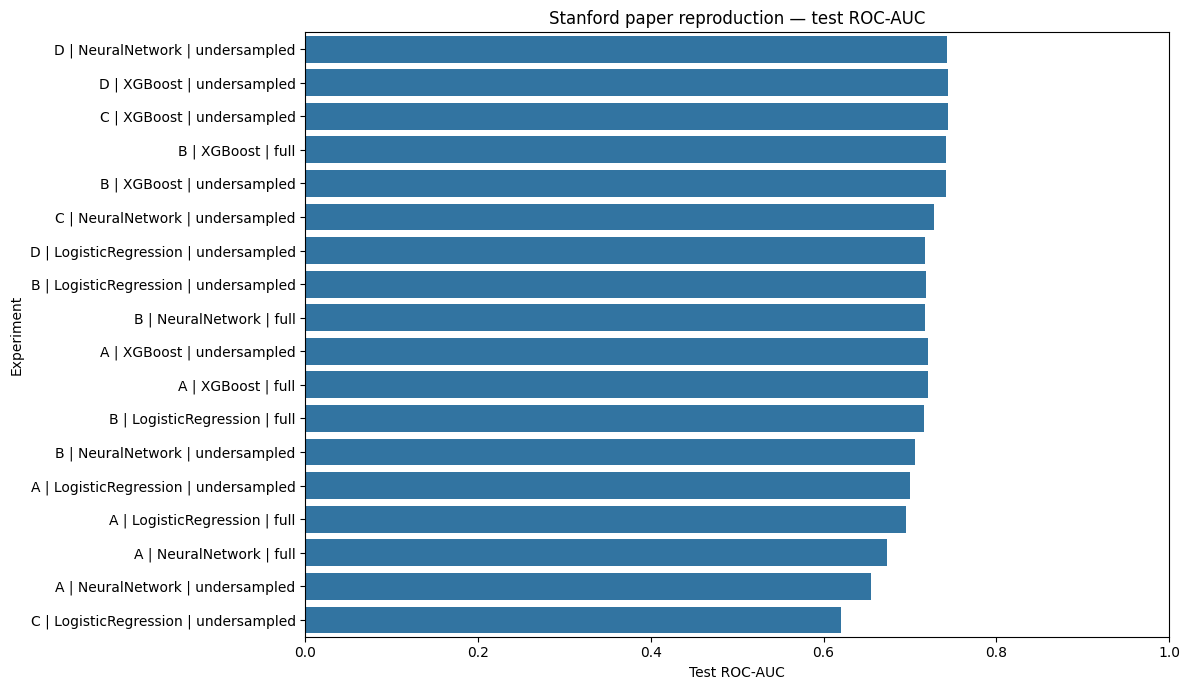

{
  "random_state": 229,
  "train_fraction": 0.69999,
  "validation_fraction": 0.15001,
  "test_fraction": 0.15,
  "rows_used": 100000,
  "quick_run": true,
  "max_rows": 100000,
  "target": "popular",
  "data_path": "/content/drive/MyDrive/goodreads_reproduction_results/goodreads_paper_features.csv",
  "feature_sets": {
    "A": [
      "user_reviews",
      "days_since_review",
      "user_rating",
      "rating_diff"
    ],
    "B": [
      "user_reviews",
      "days_since_review",
      "user_rating",
      "rating_diff",
      "num_words",
      "avg_word_len",
      "avg_sent_len",
      "pct_verbs",
      "pct_nouns",
      "pct_adj",
      "quote",
      "sentiment"
    ],
    "C": "B + CountVectorizer(max_features=10000)",
    "D": "B + TfidfVectorizer(min_df=0.0001, max_features=10000)"
  },
  "experiments_requested": 18,
  "experiments_completed": 18,
  "experiments_failed": 0,
  "note": "QUICK_RUN=True uses reduced training budgets; set False and MAX_ROWS=None for final pa

In [9]:
results_df = pd.read_csv(OUTPUT_DIR / 'model_metrics.csv')
results_df = results_df.sort_values(['validation_roc_auc', 'f1'], ascending=False)
display(results_df.round(4))

# Choose the best model using validation ROC-AUC, not test performance.
best_validation = results_df.iloc[0]
print('Best by validation ROC-AUC:', best_validation['run_name'])
print('Test ROC-AUC for that selected model:', round(float(best_validation['roc_auc']), 4))

# Save a compact comparison chart.
plt.figure(figsize=(12, 7))
chart = results_df.copy()
chart['experiment'] = chart['subset'] + ' | ' + chart['model'] + chart['undersampled'].map(
    {True: ' | undersampled', False: ' | full'}
)
sns.barplot(data=chart, x='roc_auc', y='experiment', errorbar=None)
plt.xlim(0, 1)
plt.xlabel('Test ROC-AUC'); plt.ylabel('Experiment')
plt.title('Stanford paper reproduction — test ROC-AUC')
plt.tight_layout()
plt.savefig(PLOT_DIR / 'test_auc_comparison.png', dpi=160)
plt.show()

run_manifest = {
    **split_manifest,
    'data_path': str(DATA_PATH),
    'feature_sets': {
        'A': A_COLS,
        'B': B_COLS,
        'C': 'B + CountVectorizer(max_features=10000)',
        'D': f'B + TfidfVectorizer(min_df=0.0001, max_features={MAX_TEXT_FEATURES})'
    },
    'experiments_requested': len(experiments),
    'experiments_completed': len(results),
    'experiments_failed': len(failures),
    'quick_run': QUICK_RUN,
    'note': 'QUICK_RUN=True uses reduced training budgets; set False and MAX_ROWS=None for final paper-scale run.'
}
with open(OUTPUT_DIR / 'training_manifest.json', 'w') as f:
    json.dump(run_manifest, f, indent=2)

print(json.dumps(run_manifest, indent=2))

## Notebook 03 notes for interpretation
- The test split is held out and is not used for threshold selection; predictions are classified at 0.5 to align with the paper's table.
- XGBoost uses validation early stopping. `QUICK_RUN=True` is only a smoke-test configuration, not paper-scale hyperparameter reproduction.
- The repository's TF-IDF code uses `min_df=0.0001`; this notebook caps TF-IDF at 10,000 terms to limit Colab memory. Remove `max_features=MAX_TEXT_FEATURES` only if you have enough RAM and want to test the uncapped vocabulary.
- The repository combines adjective and adverb POS tags as `pct_adj`, so the feature name follows that code.
- Logistic C/D regularization is represented using scikit-learn's inverse-strength parameter `C`; the paper reports lambda values.
- Always inspect `failed_experiments.csv` if any runs fail. The loop saves completed results incrementally.